[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_action_entropy.ipynb)


# Mechanical action and entropy: a bridge to thermodynamics

Adapted from V. L. Kulinskii's *Entropy as an adiabatic invariant* materials and the *Entropy in Action* notebook (Kulinskii and O. Yu. Orliansky).

The central question is how a mechanical invariant becomes a thermodynamic state variable. We follow the chain **action → adiabatic energy law → pressure → entropy and temperature**, first for a monatomic classical gas and then for equilibrium radiation. Prerequisites are Hamiltonian mechanics, phase portraits, and elementary partial derivatives. All temperatures below are in kelvin; $k_B$ is explicit. The source convention $k_B=1$ is recovered by measuring temperature in energy units.

**Suggested learning path.** Sections 1–5 form the core: follow the bouncing particle from phase area to the classical-gas adiabat and entropy differences. Sections 7–8 extend the same mechanical tools to radiation. Section 9 collects the comparison, section 10 states the limits of the argument, and section 11 provides exercises. The phase-volume calculation in section 6 and the chemical-potential derivation are optional connections to later thermodynamics and statistical mechanics; section 12 is an advanced supplement. These previews are not prerequisites for understanding the mechanical bridge.

The guiding question throughout is: *how far can the tools of mechanics take us?* Action invariance supplies reversible energy scaling and boundary work. Identifying equilibrium temperature requires thermal input; absolute entropy and Bose/Fermi differences require state counting; irreversible entropy growth requires a treatment beyond an individual adiabatic trajectory. These reservations mark the next steps rather than weakening the mechanical results.

## 1. Three meanings of action

Hamilton's action $\mathcal A=\int L\,dt$ is stationary under variations with fixed endpoints. The abbreviated action $W=\int\mathbf p\cdot d\mathbf q$ is stationary at fixed energy. For a closed periodic orbit we use the **cycle action**
$$J=\oint p\,dq,\qquad j=\frac{J}{2\pi}.$$
It is $J$ (or $j$) that is an adiabatic invariant. Entropy will be denoted $S$, so it is never confused with an action functional. Action has units of energy times time; entropy has units of energy divided by temperature. They are related through state counting or an integrating factor, not by equality.

The historical route runs through Boltzmann's mechanical heat theorem and Helmholtz's periodic systems, Ehrenfest's use of adiabatic invariants in the old quantum theory, and Hertz's phase-volume formulation. The latter supplies the many-particle bridge developed below.

## 2. A particle between slowly moving walls

For a particle of mass $m$ bouncing elastically between walls separated by $L$, the closed phase curve is a rectangle:
$$J=2|p|L,\qquad E=\frac{p^2}{2m}=\frac{J^2}{8mL^2}.$$
Let the right wall move with velocity $u=\dot L$, with $|u|\ll v$. Reflection in the wall frame gives $v_{\rm out}=2u-v_{\rm in}$. Averaging the small change over the round-trip time $2L/v$ gives
$$\frac{d|p|}{dt}\simeq-\frac{|p|}{L}\dot L,\qquad |p|L\simeq\mathrm{const}.$$
Thus $EL^2$ is constant during slow compression. The phase rectangle becomes narrower and taller but retains its area. The small parameter is the fractional change of $L$ per round trip. Abrupt changes and separatrix crossings fall outside this argument.

Mechanical adiabaticity means slow parameter variation. Thermodynamic adiabaticity means no heat exchange. Entropy conservation additionally requires reversibility and equilibrium; a rapid insulated process can increase entropy.

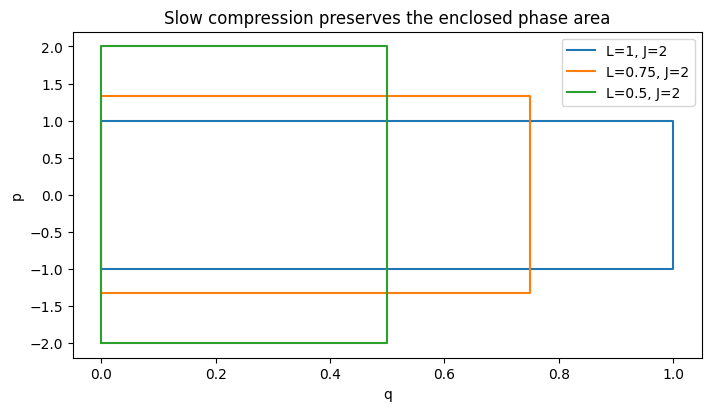

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, quad
from scipy.constants import k as k_B, h, hbar, c
from scipy.special import zeta

fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
J0 = 2.0
for length in [1.0, 0.75, 0.5]:
    momentum = J0 / (2 * length)
    ax.plot([0, length, length, 0, 0],
            [-momentum, -momentum, momentum, momentum, -momentum],
            label=f'L={length:g}, J={2*momentum*length:g}')
ax.set(xlabel='q', ylabel='p', title='Slow compression preserves the enclosed phase area')
ax.legend()
plt.show()

### Dynamic experiment: slow wall, rapid wall, and thermal wall

The original Mathematica bouncing-ball demonstration is extended here to calculate collisions, rather than prescribing a phase rectangle. Use the embedded player's play, pause, and frame controls. Each row advances through its own run at the same displayed fraction; the physical times differ and are printed beside the particle. The frame sequence samples the trajectory and may skip individual collisions in the slow run; use the finer time slider below for inspection.

**The equilibrium thermodynamic interpretation.** Compare the coherent piston speed with a characteristic molecular speed: $|u|/v_{\rm mol}\ll1$ is the mechanical slow-motion condition. Remaining near equilibrium also requires a driving time long compared with the relevant equilibration times. An insulated, reversible compression then changes the energy through ordered boundary work while preserving entropy. In contrast, a thermal boundary exchanges energy through random microscopic motion relative to its mean position; a steady net heat transfer reflects a temperature difference. Thus work and heat distinguish coherent macroscopic driving from microscopic thermal exchange. Heat need not flow rapidly on the macroscopic time scale, and molecules carrying heat need not be faster than those transferring piston work.

The rapid-wall row deliberately violates the slow-motion condition. It is a **nonequilibrium mechanical thought experiment**, not a proposed equilibrium thermodynamic compression path. For an ordinary macroscopic piston, speeds comparable to molecular speeds are outside the usual quasistatic description. This row is included only to reveal what fails when action invariance is lost; a rapid coherent wall still supplies work, rather than becoming a thermostat merely because it is fast. The slow-wall and fixed-thermal-wall rows provide the principal work-versus-heat comparison.

The left panel shows the particle and walls. The middle panel shows the particle's actual phase point and the rectangle it would trace if the walls were frozen at that instant. This **frozen-box** area is $J(t)=2|p(t)|L(t)$; during wall motion the actual trajectory is not a closed rectangle. The right panel compares $J/J_0$ and $E/E_0$. The dashed vertical line marks the end of wall motion; the last part of each compression run holds both walls fixed.

The moving right wall follows a linear ramp, with elastic reflections in its own frame:
$$v_{\rm out}=2u-v_{\rm in},\qquad
\Delta E=\frac{m}{2}\left(v_{\rm out}^2-v_{\rm in}^2\right)
=2mu\left(u-v_{\rm in}\right).$$
The code finds collision times exactly for this piecewise-linear motion. In the slow run, the action has small oscillations and is approximately conserved, while energy increases through compression work. In the rapid run, the final action depends on wall speed and the particle's initial position. A single particle can finish with either a larger or smaller action; there is no claim of monotonic entropy growth for each trajectory. The ramp starts and stops abruptly, so small endpoint corrections remain even for slow motion and vanish with wall speed.

**Work versus heat.** For a prescribed moving wall, every energy change is mechanical wall work, even when action is not conserved. We record $\Delta E=W$ and $Q=0$. For comparison, the third run holds the walls fixed and treats the right wall as a thermal boundary. Its outgoing speed is sampled from the flux-weighted Maxwell distribution
$$f(v_{\rm out})\,dv=\frac{m|v_{\rm out}|}{k_BT_b}
\exp\!\left(-\frac{mv_{\rm out}^2}{2k_BT_b}\right)dv,
\qquad v_{\rm out}<0.$$
There the wall does no displacement work and $\Delta E=Q$. Individual heat transfers fluctuate in either direction. These simulations use $m=k_B=L_0=|v_0|=1$, with $T_b=0.5$ and a reproducible random seed for the thermal run. The thermostat is an optional explicitly specified model, rather than an assumption of the preceding mechanical derivation.

There is nevertheless a useful connection to the entropy argument. Differentiating the frozen-box relation $E=J^2/(8mL^2)$ gives
$$dE=-\frac{2E}{L}\,dL+\frac{2E}{J}\,dJ.$$
For the one-degree-of-freedom equilibrium toy model, $S-S_0=k_B\ln(J/J_0)$ and $T=2E/k_B$, so the second term becomes $T\,dS$. This identifies action changes with a heat-like term when comparing neighboring equilibrium states using the reversible pressure. During rapid wall motion, that reference pressure need not equal the actual impulsive wall force; the residual must not automatically be called thermostat heat. Thermalization or averaging over an ensemble is needed before interpreting a macroscopic entropy change.

Below the saved comparison, use the parameter controls to vary ramp duration, final length, and initial position. In thermal-wall mode the length stays at one; the final-length control is ignored. Try a slow expansion as well as compression, then repeat a rapid ramp at different initial positions. Observe that the action stays constant once a moving wall stops, while a fixed thermal wall continues to change it.

Slow compression: wall work: final J/J0=1.0120, delta E=+1.1928, W=+1.1928, Q=+0.0000
Rapid compression: wall work: final J/J0=1.2571, delta E=+2.1122, W=+2.1122, Q=+0.0000
Fixed thermal wall: heat exchange: final J/J0=0.5974, delta E=-0.3215, W=+0.0000, Q=-0.3215


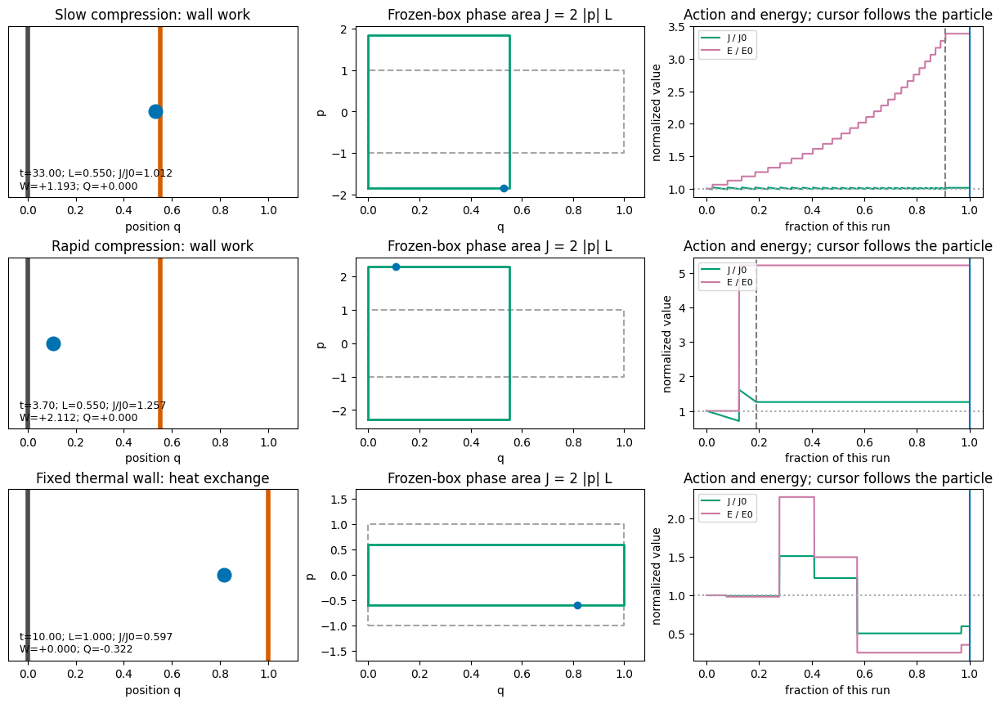

In [3]:
"""Self-contained event-driven wall and thermal-wall teaching demonstration.

The builder embeds this entire file in the notebook; no helper imports are needed.
"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import ipywidgets as widgets


def bouncing_particle(duration=30.0, final_length=0.55, x0=0.25,
                      thermal=False, bath_temperature=0.5, seed=7,
                      samples=1501):
    """Exact flights and collision times, m=k_B=L0=|v0|=1.

    Linear wall ramp followed by a stationary hold, or a fixed thermal wall.
    Wall work and heat are accumulated separately from collision energy jumps.
    """
    if duration <= 0 or final_length <= 0 or not 0 < x0 < 1:
        raise ValueError('Use positive duration and length, with 0 < x0 < 1.')
    if bath_temperature <= 0:
        raise ValueError('Bath temperature must be positive.')
    rng = np.random.default_rng(seed)
    end = duration if thermal else duration + 3.0
    times = np.linspace(0, end, samples)
    history = np.empty((samples, 6))  # x, v, L, E, W, Q
    t, x, v, length, work, heat = 0., x0, 1., 1., 0., 0.
    ramp_speed = 0. if thermal else (final_length-1)/duration
    boundary = end if thermal else duration
    u = ramp_speed
    events = []
    out_index = 0
    while t < end - 1e-12:
        left_dt = -x/v if v < 0 else np.inf
        right_dt = (length-x)/(v-u) if v > u else np.inf
        left_dt = max(0., left_dt)
        right_dt = max(0., right_dt)
        next_boundary = boundary-t
        dt = min(left_dt, right_dt, next_boundary)
        if dt < -1e-10 or not np.isfinite(dt):
            raise RuntimeError('Invalid event time.')
        stop = t+dt
        # Samples strictly before the event use the incoming velocity.
        while out_index < samples and times[out_index] < stop-1e-12:
            elapsed = times[out_index]-t
            history[out_index] = [x+v*elapsed, v, length+u*elapsed,
                                   0.5*v*v, work, heat]
            out_index += 1
        x += v*dt
        length += u*dt
        t = stop
        old_energy = 0.5*v*v
        if right_dt <= min(left_dt, next_boundary)+1e-12:
            x = length
            if thermal:
                # Flux-weighted Maxwell distribution for an outgoing wall hit.
                v = -np.sqrt(-2*bath_temperature*np.log(1-rng.random()))
                heat += 0.5*v*v-old_energy
                kind = 'heat'
            else:
                v = 2*u-v
                work += 0.5*v*v-old_energy
                kind = 'work'
            events.append((t, kind, 0.5*v*v-old_energy))
        elif left_dt <= next_boundary+1e-12:
            x = 0.
            v = -v
        if t >= boundary-1e-12:
            u = 0.
            boundary = end
        if t >= end-1e-12:
            break
    while out_index < samples:
        elapsed = times[out_index]-t
        history[out_index] = [x+v*elapsed, v, length+u*elapsed,
                               0.5*v*v, work, heat]
        out_index += 1
    q, momentum, lengths, energy, wall_work, bath_heat = history.T
    action = 2*np.abs(momentum)*lengths
    assert np.all(q >= -1e-9) and np.all(q <= lengths+1e-9)
    assert np.allclose(energy-0.5, wall_work+bath_heat, atol=1e-10)
    return dict(t=times, q=q, p=momentum, L=lengths, E=energy,
                J=action, W=wall_work, Q=bath_heat, events=events,
                duration=duration, thermal=thermal)


cases = [
    ('Slow compression: wall work', bouncing_particle(30.0)),
    ('Rapid compression: wall work', bouncing_particle(0.7)),
    ('Fixed thermal wall: heat exchange',
     bouncing_particle(10.0, thermal=True)),
]

# Checks distinguish collision physics and energy bookkeeping, not just drawing.
fixed = bouncing_particle(5., final_length=1.)
assert np.allclose(fixed['J'], 2.) and np.allclose(fixed['E'], 0.5)
slow_limit = bouncing_particle(300.)
assert abs(slow_limit['J'][-1]/2-1) < 0.005
for _, data in cases[:2]:
    assert np.allclose(data['Q'], 0.)
assert np.allclose(cases[2][1]['W'], 0.)
assert any(abs(e[2]) > 0 for e in cases[2][1]['events'])
for label, data in cases:
    print(f"{label}: final J/J0={data['J'][-1]/2:.4f}, "
          f"delta E={data['E'][-1]-0.5:+.4f}, "
          f"W={data['W'][-1]:+.4f}, Q={data['Q'][-1]:+.4f}")


def comparison_canvas():
    fig, axes = plt.subplots(3, 3, figsize=(12, 8.5), layout='constrained')
    artists = []
    for row, (label, data) in enumerate(cases):
        space, phase, record = axes[row]
        space.set(xlim=(-0.08, 1.12), ylim=(-0.45, 0.45),
                  xlabel='position q', title=label)
        space.set_yticks([])
        space.axvline(0, color='0.3', linewidth=4)
        wall = space.axvline(1, color='#D55E00', linewidth=4)
        ball, = space.plot([], [], 'o', color='#0072B2', markersize=12)
        info = space.text(0.04, 0.05, '', transform=space.transAxes, fontsize=9)
        max_p = max(1.1, np.max(np.abs(data['p']))*1.12)
        phase.set(xlim=(-0.05, 1.08), ylim=(-max_p, max_p),
                  xlabel='q', ylabel='p', title='Frozen-box phase area J = 2 |p| L')
        phase.plot([0, 1, 1, 0, 0], [-1, -1, 1, 1, -1],
                   '--', color='0.65', label='Initial rectangle')
        rectangle, = phase.plot([], [], color='#009E73', linewidth=2)
        dot, = phase.plot([], [], 'o', color='#0072B2', markersize=6)
        fraction = data['t']/data['t'][-1]
        record.plot(fraction, data['J']/2, color='#009E73', label='J / J0')
        record.plot(fraction, data['E']/0.5, color='#CC79A7', label='E / E0')
        record.axhline(1, color='0.65', linestyle=':')
        if not data['thermal']:
            record.axvline(data['duration']/data['t'][-1], color='0.5', linestyle='--')
        cursor = record.axvline(0, color='#0072B2')
        record.set(xlabel='fraction of this run', ylabel='normalized value',
                   title='Action and energy; cursor follows the particle')
        record.legend(loc='upper left', fontsize=8)
        artists.append((wall, ball, info, rectangle, dot, cursor))
    return fig, artists


def update_comparison(fraction, artists):
    for (_, data), (wall, ball, info, rectangle, dot, cursor) in zip(cases, artists):
        i = min(int(fraction*(len(data['t'])-1)), len(data['t'])-1)
        length, p, q = data['L'][i], data['p'][i], data['q'][i]
        wall.set_xdata([length, length])
        ball.set_data([q], [0])
        magnitude = abs(p)
        rectangle.set_data([0, length, length, 0, 0],
                           [-magnitude, -magnitude, magnitude, magnitude, -magnitude])
        dot.set_data([q], [p])
        cursor.set_xdata([fraction, fraction])
        info.set_text(f"t={data['t'][i]:.2f}; L={length:.3f}; J/J0={data['J'][i]/2:.3f}\n"
                      f"W={data['W'][i]:+.3f}; Q={data['Q'][i]:+.3f}")
    return tuple(a for group in artists for a in group)


# A saved still provides a readable fallback for viewers blocking JavaScript.
fig, artists = comparison_canvas()
update_comparison(1., artists)
plt.show()

# The embedded player runs without a Python kernel or any external media files.
fig, artists = comparison_canvas()
animation = FuncAnimation(fig, lambda f: update_comparison(f, artists),
                          frames=np.linspace(0, 1, 121), interval=100, blit=False)
with plt.rc_context({'animation.embed_limit': 40, 'figure.dpi': 75}):
    animation_html = animation.to_jshtml(default_mode='once')
plt.close(fig)
display(HTML(animation_html))


def explore_wall(mode='Moving wall', duration=5., final_length=0.55,
                 initial_position=0.25, fraction=0.5):
    data = bouncing_particle(duration, final_length, initial_position,
                              thermal=(mode == 'Thermal wall'))
    i = min(int(fraction*(len(data['t'])-1)), len(data['t'])-1)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), layout='constrained')
    q, p, length = data['q'][i], data['p'][i], data['L'][i]
    axes[0].axvline(0, color='0.3', linewidth=4)
    axes[0].axvline(length, color='#D55E00', linewidth=4)
    axes[0].plot(q, 0, 'o', color='#0072B2', markersize=12)
    axes[0].set(xlim=(-0.08, 1.2), ylim=(-0.5, 0.5), xlabel='q',
                title=f"t={data['t'][i]:.2f}; L={length:.3f}")
    axes[0].set_yticks([])
    axes[1].plot([0, length, length, 0, 0],
                 [-abs(p), -abs(p), abs(p), abs(p), -abs(p)], color='#009E73')
    axes[1].plot(q, p, 'o', color='#0072B2')
    axes[1].set(xlabel='q', ylabel='p', title=f"Frozen area J/J0={data['J'][i]/2:.3f}")
    axes[2].plot(data['t'], data['J']/2, label='J / J0', color='#009E73')
    axes[2].plot(data['t'], data['E']/0.5, label='E / E0', color='#CC79A7')
    axes[2].axvline(data['t'][i], color='#0072B2')
    axes[2].set(xlabel='t', title=f"W={data['W'][i]:+.3f}; Q={data['Q'][i]:+.3f}")
    axes[2].legend()
    plt.show()


mode_control = widgets.Dropdown(options=['Moving wall', 'Thermal wall'], description='Boundary')
duration_control = widgets.FloatLogSlider(value=5, base=10, min=-0.7, max=2,
                                          description='Duration', continuous_update=False)
length_control = widgets.FloatSlider(value=0.55, min=0.3, max=1.5, step=0.05,
                                    description='Final L', continuous_update=False)
position_control = widgets.FloatSlider(value=0.25, min=0.05, max=0.95, step=0.05,
                                      description='Initial q', continuous_update=False)
time_control = widgets.FloatSlider(value=0.5, min=0, max=1, step=0.01,
                                  description='Run fraction', continuous_update=False)
widget_output = widgets.interactive_output(explore_wall, {
    'mode': mode_control, 'duration': duration_control, 'final_length': length_control,
    'initial_position': position_control, 'fraction': time_control})
display(widgets.VBox([widgets.HBox([mode_control, duration_control]),
                      widgets.HBox([length_control, position_control]),
                      time_control, widget_output]))

## 3. The oscillator and Ehrenfest's invariant

For $H=p^2/(2m)+m\omega^2q^2/2$, the phase curve is an ellipse with semiaxes $\sqrt{2E/(m\omega^2)}$ and $\sqrt{2mE}$. Its area is
$$J=\frac{2\pi E}{\omega},\qquad j=\frac{E}{\omega}.$$
Hence slowly varying $\omega$ preserves $E/\omega$, provided $|\dot\omega|/\omega^2\ll1$. The source's expression $E\omega$ is a typo: it has the wrong dimensions and the wrong scaling. In action–angle coordinates $H=H(j,\lambda)$ and $\dot\theta=\partial H/\partial j$. Averaging over the fast angle explains why $j$ changes only weakly under slow variation of $\lambda$.

The next experiment solves the time-dependent equations directly. Instantaneous $E/\omega$ has small oscillations even for a slow ramp; adiabatic invariance is an asymptotic statement.

Duration 2: final relative action change 6.670e-02
Duration 100: final relative action change 1.231e-04


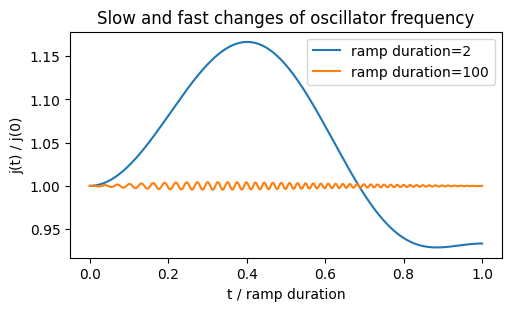

In [4]:
def oscillator_ramp(duration):
    def omega(t):
        return 1 + 0.5 * (1 - np.cos(np.pi*t/duration))
    times = np.linspace(0, duration, 4001)
    sol = solve_ivp(lambda t, y: [y[1], -omega(t)**2*y[0]],
                    (0, duration), [1., 0.], t_eval=times,
                    rtol=1e-10, atol=1e-12, max_step=0.05)
    assert sol.success
    w = omega(times)
    energy = (sol.y[1]**2 + w**2*sol.y[0]**2)/2
    return times/duration, energy/w, energy

fig, ax = plt.subplots(figsize=(5, 3), layout='constrained')
errors = {}
for duration in [2., 100.]:
    t, action, energy = oscillator_ramp(duration)
    errors[duration] = abs(action[-1]/action[0]-1)
    ax.plot(t, action/action[0], label=f'ramp duration={duration:g}')
    print(f'Duration {duration:g}: final relative action change {errors[duration]:.3e}')
assert errors[100.] < 1e-3
assert errors[100.] < errors[2.]
ax.set(xlabel='t / ramp duration', ylabel='j(t) / j(0)', title='Slow and fast changes of oscillator frequency')
ax.legend()
plt.show()

## 4. A classical gas: the mechanical equation of the adiabat

Take $N$ noninteracting monatomic particles in a $d$-dimensional cubical box, $V=L^d$. Compress it uniformly, keeping its shape. Each component action $J_{i\alpha}=2|p_{i\alpha}|L$ is conserved to adiabatic accuracy. Therefore
$$E=\sum_{i=1}^{N}\sum_{\alpha=1}^{d}\frac{p_{i\alpha}^2}{2m},\qquad
I_{\rm cl}=EV^{2/d}=\sum_{i,\alpha}\frac{J_{i\alpha}^2}{8m}=\mathrm{const}.$$
The sum runs over all $dN$ translational degrees of freedom. $I_{\rm cl}$ is built from squared actions; it is not itself a cycle action.

The force on a moving boundary is obtained by differentiating energy at fixed actions. For isotropic equilibrium this gives the scalar pressure
$$P=-\left(\frac{\partial E}{\partial V}\right)_{I_{\rm cl},N}=\frac{2E}{dV}.$$
With equipartition $E=dNk_BT/2$,
$$PV=Nk_BT,\qquad TV^{2/d}=\mathrm{const},\qquad PV^{\gamma}=\mathrm{const},\qquad \gamma=1+\frac{2}{d}.$$
In three dimensions $\gamma=5/3$. Anisotropic wall motion preserves separate component actions and generally produces unequal directional pressures in a collisionless gas. A single equilibrium temperature requires an equilibrium ensemble or a mechanism for equilibration. The fixed-shape scaling does not by itself prove thermalization.

## 5. From the invariant to the first law and entropy

Between neighboring equilibrium states with fixed $N$,
$$dE=-P\,dV+\frac{E}{I_{\rm cl}}\,dI_{\rm cl}.$$
The remaining energy change is the reversible heat input $\delta Q_{\rm rev}=dE+P\,dV$. Since $E/T=dNk_B/2$, its integrating factor is $1/T$:
$$dS=\frac{dE+P\,dV}{T}=\frac{d}{2}Nk_B\,d\ln{I_{\rm cl}}.$$
Only ratios belong inside logarithms. For a reference state with the same $N$,
$$S-S_0=\frac{d}{2}Nk_B\ln{\left(\frac{I_{\rm cl}}{I_0}\right)}
=Nk_B\ln{\left(\frac{V}{V_0}\right)}+\frac{d}{2}Nk_B\ln{\left(\frac{T}{T_0}\right)}.$$
Equivalently,
$$E(S,V,N)=E_0\left(\frac{V_0}{V}\right)^{2/d}
\exp{\left(\frac{2(S-S_0)}{dNk_B}\right)}.$$
Here $E_0$ is the reference energy, not an arbitrary additive constant. Differentiating gives $T=(\partial E/\partial S)_{V,N}$ and $P=-(\partial E/\partial V)_{S,N}$. This is the fundamental relation of thermodynamics constructed from the mechanical scaling.

The invariant alone determines the entropy differences at fixed $N$ once the thermal scale is fixed by equipartition. It does not fix absolute entropy, the dependence on particle number, or the chemical potential.

## 6. Optional connection: phase volume as the many-particle version of action

For $f=dN$ canonical degrees of freedom, define the dimensionless cumulative phase volume
$$\Phi(E,V,N)=\frac{1}{N!h^{dN}}\int_{H\le E}d^{dN}q\,d^{dN}p.$$
For the classical ideal gas the position integral is $V^N$ and the momentum region is a $dN$-ball:
$$\Phi=\frac{V^N(2\pi mE)^{dN/2}}{N!h^{dN}\Gamma(dN/2+1)}
\ \propto\ \left(EV^{2/d}\right)^{dN/2}.$$
Thus $S_G=k_B\ln\Phi$ reproduces the preceding entropy differences. A reference action scale makes the count dimensionless; quantum mechanics selects $h$, and the $N!$ correction gives the appropriate indistinguishable-particle counting.

For a general Hamiltonian with a slowly varying parameter $\lambda$, differentiation gives
$$\partial_\lambda\Phi=-\partial_E\Phi\,
\left\langle\partial_\lambda H\right\rangle_E.$$
If the slow evolution samples the equilibrium energy surface, then
$$\frac{dE}{d\lambda}=\left\langle\partial_\lambda H\right\rangle_E
\quad\Longrightarrow\quad\frac{d\Phi}{d\lambda}=0.$$
This is the Hertz adiabatic-invariance argument. Ergodic sampling is a sufficient hypothesis; an integrable ideal gas needs its separate action argument. Liouville's theorem preserves a transported phase volume even under rapid Hamiltonian motion, but that transported region need not be the equilibrium sublevel set of the new Hamiltonian.

The cumulative volume $\Phi$ differs from the density of states $\partial_E\Phi$. Their logarithms give volume and shell entropies, respectively; they agree at leading thermodynamic order for this gas but differ at finite $N$. The volume convention is used consistently here. See [Campisi (2005)](https://doi.org/10.1016/j.shpsb.2005.01.001).

For $d=3$, Stirling's approximation yields the Sackur–Tetrode form in the dilute classical regime,
$$S\simeq Nk_B\left[\ln{\left(\frac{V}{N}\left(\frac{4\pi mE}{3Nh^2}\right)^{3/2}\right)}+\frac52\right].$$
It is extensive when $E,V,N$ are scaled together. A bare $N\ln I_{\rm cl}$ with a constant independent of $N$ misses this property.

### Optional connection: chemical potential and thermodynamic functions

When particle number can change, the fundamental differential is
$$dE=T\,dS-P\,dV+\mu\,dN,\qquad
\mu=\left(\frac{\partial E}{\partial N}\right)_{S,V}.$$
For an extensive equilibrium system, Euler's theorem gives
$$E=TS-PV+\mu N.$$
The Helmholtz free energy $F=E-TS$ satisfies $dF=-S\,dT-P\,dV+\mu\,dN$; the enthalpy $\mathcal H=E+PV$ satisfies $d\mathcal H=T\,dS+V\,dP+\mu\,dN$; and the Gibbs free energy $G=E+PV-TS$ satisfies $dG=-S\,dT+V\,dP+\mu\,dN$ and $G=\mu N$ for this one-component gas. The grand potential $\Omega_{\rm grand}=F-\mu N=-PV$ is distinct from a phase volume.

For structureless classical particles in three dimensions, introduce the thermal wavelength
$$\lambda_T=\frac{h}{\sqrt{2\pi mk_BT}},\qquad n=\frac NV.$$
The Sackur–Tetrode entropy becomes
$$S=Nk_B\left[\frac52-\ln{\left(n\lambda_T^3\right)}\right],$$
so $E=3Nk_BT/2$ gives
$$F=Nk_BT\left[\ln{\left(n\lambda_T^3\right)}-1\right].$$
At fixed $T,V$, $n$ changes with $N$, and differentiation yields
$$\boxed{\mu=\left(\frac{\partial F}{\partial N}\right)_{T,V}
=k_BT\ln{\left(n\lambda_T^3\right)}}.$$
The same result follows directly from the entropy representation. At fixed $E,V$, the thermal wavelength obeys $\lambda_T^3\propto(N/E)^{3/2}$, hence
$$\left(\frac{\partial S}{\partial N}\right)_{E,V}
=-k_B\ln{\left(n\lambda_T^3\right)},\qquad
\mu=-T\left(\frac{\partial S}{\partial N}\right)_{E,V}.$$
This independently recovers the derivative of $E(S,V,N)$ because rearranging the fundamental differential gives $dS=dE/T+(P/T)dV-(\mu/T)dN$.

In the dilute classical regime $n\lambda_T^3\ll1$, the logarithm is negative, so $\mu<0$. Equivalently, the fugacity $z=\exp(\mu/k_BT)=n\lambda_T^3\ll1$. At fixed $E,V$, adding a particle increases the available entropy, giving the negative sign through the last derivative. Extending this classical formula into $n\lambda_T^3\gtrsim1$ is invalid; quantum degeneracy must then be included. With a constant internal degeneracy $g$, replace $n\lambda_T^3$ by $n\lambda_T^3/g$.

The sign assumes the usual single-particle kinetic-energy zero. Shifting each particle energy by a constant shifts $\mu$ by the same constant. Thus the physical distinction from blackbody radiation is the independent particle-number constraint, not the sign in isolation. The chemical potential of an ordinary dilute gas can be negative even when its $N$ is held fixed: it is a derivative of the family of equilibrium states with respect to $N$.

n lambda_T^3 = 4.056e-10
mu / (k_B T) = -21.625706


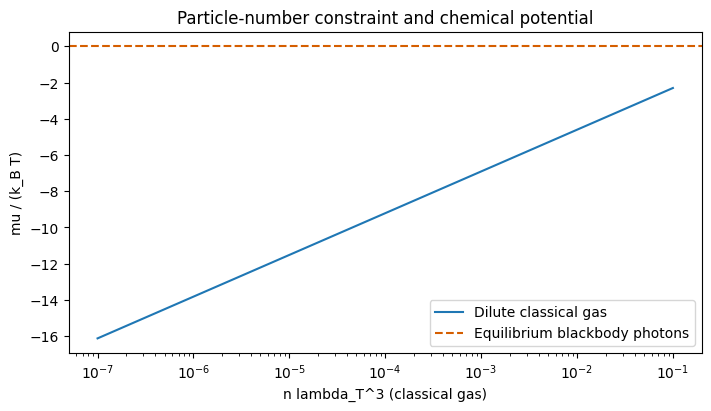

In [5]:
# Numerically check mu = (dF/dN)_(T,V) in the dilute regime.
mass = 6.6335209e-26  # representative monatomic mass, kg
temperature = 300.0
number = 1.0e20
box_volume = 1.0e-3
thermal_wavelength = h / np.sqrt(2*np.pi*mass*k_B*temperature)
def free_energy(N):
    return N*k_B*temperature*(np.log(N*thermal_wavelength**3/box_volume)-1)
step = number*1e-4
mu_fd = (free_energy(number+step)-free_energy(number-step))/(2*step)
mu_exact = k_B*temperature*np.log(number*thermal_wavelength**3/box_volume)
assert np.isclose(mu_fd, mu_exact, rtol=1e-8)
assert mu_exact < 0
print(f'n lambda_T^3 = {number*thermal_wavelength**3/box_volume:.3e}')
print(f'mu / (k_B T) = {mu_exact/(k_B*temperature):.6f}')

degeneracy_parameter = np.logspace(-7, -1, 250)
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.semilogx(degeneracy_parameter, np.log(degeneracy_parameter), label='Dilute classical gas')
ax.axhline(0, color='#D55E00', linestyle='--', label='Equilibrium blackbody photons')
ax.set(xlabel=r'n lambda_T^3 (classical gas)', ylabel='mu / (k_B T)',
       title='Particle-number constraint and chemical potential')
ax.legend()
plt.show()

## 7. Radiation: the same mechanics, a different entropy

Electromagnetic cavity modes are harmonic oscillators. Under slow uniform dilation, each fixed mode index has $\omega_\nu\propto c/L$ and $j_\nu=E_\nu/\omega_\nu$ is invariant. Summing the mode energies gives
$$I_\gamma=EV^{1/d}=\mathrm{const},\qquad
P=-\left(\frac{\partial E}{\partial V}\right)_{I_\gamma}=\frac{E}{dV}.$$
Equivalently, photons have dispersion $\varepsilon=c|p|$: conserving $pL$ makes energy scale as $L^{-1}$ rather than $L^{-2}$. Consequently $PV^{1+1/d}$ is constant. For $d=3$ the adiabatic exponent is $4/3$.

Here $4/3$ means the exponent of $PV^\gamma$ on an isentrope. It should not be interpreted as $C_P/C_V$ for equilibrium blackbody radiation: pressure fixes temperature, so the usual independent constant-pressure temperature variation is unavailable.

The mechanical argument obtains the adiabat and pressure–energy relation. It does not obtain the equilibrium spectrum or the radiation constant: classical equipartition of infinitely many field modes produces the ultraviolet catastrophe. Planck statistics supplies the additional physical input.

## 8. Blackbody temperature and entropy

For three-dimensional equilibrium radiation, photon number is not an independent conserved thermodynamic coordinate, and $\mu=0$. Extensivity gives the Euler relation $E=TS-PV$; hence
$$S=\frac{4E}{3T}.$$
We can formulate the argument for the radiation system itself, without introducing an external particle reservoir. Temporarily label constrained equilibrium states by $S(E,V,N_\gamma)$. If photon number is not an independent conserved constraint, equilibrium at fixed $E,V$ maximizes entropy over the allowed $N_\gamma$ as well. At an interior maximum,
$$0=\left(\frac{\partial S}{\partial N_\gamma}\right)_{E,V}
=-\frac{\mu_\gamma}{T},\qquad\boxed{\mu_\gamma=0}.$$
Equivalently, at fixed $T,V$ the equilibrium free energy is stationary with respect to the unconstrained photon number. Emission and absorption at walls are a familiar realization, rather than the premise of this thermodynamic derivation. The essential assumption is equilibrium without a separately imposed photon-number constraint. An exactly noninteracting radiation field does not dynamically explore all occupations by itself; this entropy argument specifies the equilibrium ensemble, not a thermalization mechanism. A number-constrained or nonequilibrium photon population need not have the blackbody value.

Consequently blackbody radiation has
$$F=-PV=-\frac13aVT^4,\qquad G=F+PV=0,\qquad
\Omega_{\rm grand}=F.$$
Its equilibrium fundamental relation is $E(S,V)$, with no independent $N_\gamma$ coordinate. In contrast, the material gas has $E(S,V,N)$ and a nonzero $\mu\,dN$ term whenever its particle number changes. The full blackbody distribution is Bose–Einstein with zero chemical potential; its mean number follows from $T,V$ rather than being supplied as an extra equation of state.

### The thermodynamic limit and the lowest photon energy

In a finite cavity the electromagnetic spectrum is discrete. For a family of similar cavities, the lowest nonzero photon mode has
$$\varepsilon_{\min}=\hbar\omega_{\min}\sim\frac{\hbar c}{L}
\sim\hbar c\,V^{-1/3}.$$
The proportionality constant depends on geometry and boundary conditions. In the thermodynamic limit $V\to\infty$ at fixed $T$, both the lowest nonzero mode energy and the characteristic frequency spacing tend to zero. An additional photon can then carry arbitrarily little energy; the continuum mode approximation used in the blackbody integrals becomes appropriate. This is an important physical connection between cavity mechanics and bulk radiation thermodynamics.

The thermodynamic definition makes the connection precise. At fixed entropy and volume, $\mu\,dN$ is the reversible energy increment associated with changing particle number:
$$\mu=\left(\frac{\partial F}{\partial N}\right)_{T,V}
=\left(\frac{\partial E}{\partial N}\right)_{S,V}$$
Adding a photon of frequency $\omega$ contributes $\hbar\omega$ to the energy, but that addition alone does not specify an equilibrium variation at fixed entropy. The soft-mode argument establishes that the spectral energy threshold for changing photon number tends to zero; to identify the thermodynamic derivative, we must also account for the entropy change and the permitted equilibrium constraints.

There is also a direct statistical connection. For ideal bosons with a temporarily constrained number,
$$\overline n_\nu=\frac{1}{\exp{\left[(\varepsilon_\nu-\mu)/(k_BT)\right]}-1}.$$
Positive finite occupations require $\mu<\varepsilon_{\min}$ in a finite cavity. As $\varepsilon_{\min}\to0$, the bulk upper bound becomes $\mu\le0$. Thus the vanishing lowest frequency is directly relevant: it fixes the upper bound on the chemical potential at zero. It does not select equality, because a number-constrained massless Bose gas can have $\mu<0$. Removing the independent number constraint and maximizing entropy selects $\mu=0$, as derived above. The occupation bound is discussed in [Hadley's ideal-boson thermodynamics notes](https://lampz.tugraz.at/~hadley/ss2/emfield/thermo/thermo.php).

Together these statements provide a route with minimal external assumptions: cavity mechanics gives an arbitrarily small energy threshold and the bulk bound $\mu\le0$; equilibrium with unconstrained photon number gives $\mu=0$. At that equilibrium, number adjustment has zero first-order free-energy cost, or zero first-order energy cost at fixed entropy. This does not imply zero energy for a typical photon, whose mean energy is $2.701\,k_BT$. In a finite equilibrium cavity unconstrained number still gives $\mu=0$; the thermodynamic limit explains the gapless spectrum and the continuum formulas.
One can now derive the temperature law without assuming a fixed photon number. Write $E=Ve(T)$ and differentiate $S=4Ve(T)/(3T)$ at fixed $V$. The first law $dE=T\,dS$ implies
$$e'(T)=\frac43\left(e'(T)-\frac{e(T)}{T}\right)
\quad\Longrightarrow\quad e(T)=aT^4.$$
The integration constant $a$ requires microscopic input. Planck's spectrum fixes it, as described in [Tong's blackbody lecture](https://www.damtp.cam.ac.uk/user/tong/statphys/statmechhtml/S3.html):
$$a=\frac{\pi^2k_B^4}{15\hbar^3c^3},\qquad
E=aVT^4,\quad P=\frac{a}{3}T^4,\quad S=\frac43aVT^3,\quad C_V=4aVT^3.$$
The energy-density constant $a$ is related to the Stefan–Boltzmann flux constant by $\sigma_{\rm SB}=ac/4$.

On a reversible radiation adiabat, $TV^{1/3}$ is constant. Eliminating $T$ gives a power law rather than a logarithm:
$$S=\frac43a^{1/4}E^{3/4}V^{1/4}
=\frac43a^{1/4}I_\gamma^{3/4}.$$
Indeed,
$$dE=-P\,dV+\frac{E}{I_\gamma}\,dI_\gamma=-P\,dV+T\,dS.$$
More generally, equilibrium massless radiation in $d$ dimensions has $E=a_dVT^{d+1}$ and
$$S=\frac{d+1}{d}a_d^{1/(d+1)}I_\gamma^{d/(d+1)}.$$
These results assume an equilibrium radiation family and uniform cavity scaling; conserving mode actions for an arbitrary nonthermal field does not assign it a blackbody temperature.

### Photon number is not a count of all cavity modes

For a Planck distribution the mean photon number is
$$\overline N_\gamma=\frac{2\zeta(3)}{\pi^2}V
\left(\frac{k_BT}{\hbar c}\right)^3,\qquad
\frac{E}{\overline N_\gamma k_BT}=\frac{\pi^4}{30\zeta(3)}\simeq2.701.$$
Therefore $S/(k_B\overline N_\gamma)\simeq3.602$, not $4/3$. The source's effective variable $N_{\rm eff}=E/(k_BT)$ is proportional to the true photon number, but is not that number.

Along an equilibrium reversible adiabat, $VT^3$ and thus $\overline N_\gamma$ remain constant. This is a consequence of the Planck scaling, not a general photon-number conservation law. Photon emission and absorption can occur at the walls, and other processes change the mean photon number. Mode indices label oscillators; their occupation numbers count photons.

In [6]:
# Check the Planck integrals independently of the quoted constants.
def bose_integrand(x, power):
    return x**power * np.exp(-x) / (-np.expm1(-x))
number_integral = quad(lambda x: bose_integrand(x, 2), 0, np.inf)[0]
energy_integral = quad(lambda x: bose_integrand(x, 3), 0, np.inf)[0]
assert np.isclose(number_integral, 2*zeta(3), rtol=1e-10)
assert np.isclose(energy_integral, np.pi**4/15, rtol=1e-10)
mean_energy_ratio = energy_integral / number_integral
print(f'Mean photon energy / (k_B T) = {mean_energy_ratio:.6f}')
print(f'Entropy / (k_B mean photon number) = {4*mean_energy_ratio/3:.6f}')

Mean photon energy / (k_B T) = 2.701178
Entropy / (k_B mean photon number) = 3.601571


### Looking ahead: Bose and Fermi gases

The mechanical arguments above anticipate results that statistical mechanics will derive more precisely. Three qualitative features are useful to remember.

* **Both kinds of particles have a classical dilute limit.** At low occupation, Bose and Fermi gases approach the same Maxwell–Boltzmann statistics. Their chemical potential is then negative, with the lowest single-particle energy chosen as zero.
* **Bosons can share a state in large numbers.** For radiation, highly occupied low-frequency modes behave like classical waves. When $\hbar\omega\ll k_BT$, their mean energy approaches $k_BT$ per oscillator: the Rayleigh–Jeans limit. This classical-wave limit is different from the dilute classical-particle limit. Applying it to all frequencies gives the ultraviolet catastrophe; Planck's law resolves that failure.
* **Fermions obey exclusion.** Each single-particle state can contain at most one identical fermion. At low temperature, particles fill an increasing range of energies, producing the Fermi energy and pressure even at zero temperature. A strongly degenerate ideal Fermi gas has positive chemical potential relative to the ground energy; a dilute Fermi gas has negative chemical potential.

For an ideal Bose gas, the chemical potential cannot exceed the lowest single-particle energy. In the bulk convention this gives $\mu\le0$. A number-constrained Bose gas can approach this boundary through condensation. Equilibrium blackbody radiation has $\mu=0$ because photon number is unconstrained; this should not be confused with fixed-number Bose condensation.

These are signposts, rather than additional prerequisites. The exact Bose–Einstein and Fermi–Dirac distributions, the condensation criterion, and the temperature dependence of the Fermi chemical potential belong to the later statistical-mechanics course. See [Tong's quantum-gas lectures](https://www.damtp.cam.ac.uk/user/tong/statphys/statmechhtml/S3.html).

## 9. Compare the two reversible adiabats

| Quantity, in three dimensions | Monatomic classical gas, fixed $N$ | Equilibrium photon gas, $\mu=0$ |
|---|---|---|
| Microscopic scaling | $\varepsilon\propto p^2$ | $\varepsilon\propto |p|$ |
| Mechanical invariant | $I_{\rm cl}=EV^{2/3}$ | $I_\gamma=EV^{1/3}$ |
| Pressure | $2E/(3V)$ | $E/(3V)$ |
| Thermal energy | $3Nk_BT/2$ | $aVT^4$ |
| Chemical potential | $k_BT\ln(n\lambda_T^3)<0$ in the dilute regime | $0$ at blackbody equilibrium |
| Independent fundamental variables | $S,V,N$ | $S,V$ |
| Helmholtz free energy | $Nk_BT[\ln(n\lambda_T^3)-1]$ | $-aVT^4/3$ |
| Entropy versus invariant | $\Delta S=(3Nk_B/2)\ln(I_{\rm cl}/I_0)$ | $S=(4/3)a^{1/4}I_\gamma^{3/4}$ |
| Temperature along an isentrope | $T\propto V^{-2/3}$ | $T\propto V^{-1/3}$ |
| Adiabatic exponent | $5/3$ | $4/3$ |

The numerical comparison below uses ratios to each system's own reference state. Their physical units and entropy normalizations are different.

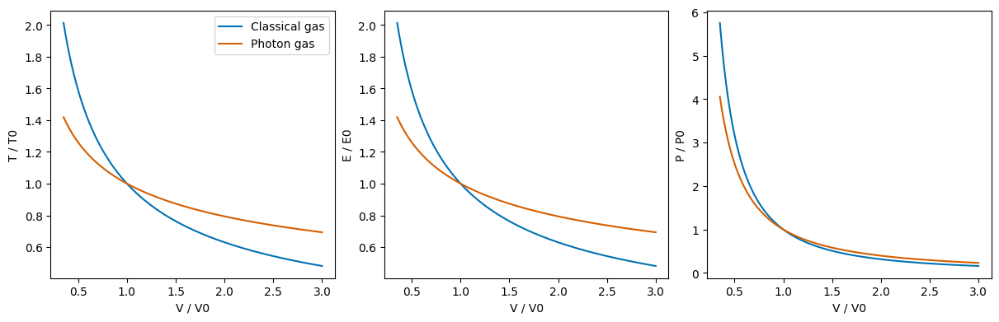

In [7]:
volume = np.linspace(0.35, 3.0, 300)  # V / V0
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout='constrained')
for label, power, color in [('Classical gas', 2/3, '#0072B2'),
                             ('Photon gas', 1/3, '#D55E00')]:
    temperature = volume**(-power)
    energy = volume**(-power)
    pressure = volume**(-1-power)
    axes[0].plot(volume, temperature, color=color, label=label)
    axes[1].plot(volume, energy, color=color, label=label)
    axes[2].plot(volume, pressure, color=color, label=label)
    assert np.allclose(energy*volume**power, 1)
assert np.allclose(np.log(volume)+1.5*np.log(volume**(-2/3)), 0, atol=1e-14)
assert np.allclose(volume*(volume**(-1/3))**3, 1)
for ax, ylabel in zip(axes, ['T / T0', 'E / E0', 'P / P0']):
    ax.set(xlabel='V / V0', ylabel=ylabel)
axes[0].legend()
plt.show()

## 10. What this bridge does—and does not—establish

The identity $dE=T\,dS-P\,dV$ connects mechanical boundary work with equilibrium changes of the action-derived state variable. It explains the existence of entropy and its constancy on reversible adiabats under the stated assumptions. It does not prove that every isolated trajectory thermalizes or that irreversible entropy increase follows from action invariance alone.

For example, a classical ideal gas freely expanding into vacuum is insulated and does no work. Its energy and final equilibrium temperature remain unchanged, but
$$\Delta S=Nk_B\ln{\left(\frac{V_f}{V_i}\right)}>0.$$
The walls have not undergone the slow compression/expansion used in the action argument. During relaxation a single equilibrium pressure and temperature need not describe the state. Fine-grained Hamiltonian ensemble entropy is conserved under Liouville evolution; thermodynamic entropy compares equilibrated macrostates and includes the loss of microscopic constraints.

The same warning applies to abruptly expanding radiation: the final state must be specified and equilibrated before an equilibrium entropy formula is used.

## 11. Exercises and short answers

1. Compute the particle cycle action and oscillator cycle action from their phase portraits. Why can neither $E\omega$ nor $EV^{2/3}$ be called the same quantity as $J$?
2. In $d$ dimensions, derive the classical heat capacities and show that $C_P/C_V=1+2/d$.
3. For fixed-$N$ classical particles with homogeneous dispersion $\varepsilon=A|p|^s$, use uniform scaling to obtain $EV^{s/d}=\mathrm{const}$ and $PV=sE/d$. Assuming classical equilibrium statistics, derive the entropy difference.
4. Starting with the classical $E(S,V,N)$ above, recover both conjugate variables by differentiation.
5. Derive $E(S,V)$ for three-dimensional radiation and verify $T$ and $P$ by differentiation.
6. Explain why a conserved mean photon number on a blackbody adiabat does not imply $\mu\ne0$ or photon conservation in all processes.
7. Increase and decrease the oscillator ramp duration. Compare the maximum instantaneous deviation with the final deviation; explain why they need not be equal.
8. Double the volume by reversible adiabatic expansion and by free expansion. Compare the final temperature and entropy of a classical gas.
9. Derive $\mu$ from $F(T,V,N)$ and from $S(E,V,N)$. Explain why $\mu<0$ for the dilute classical gas, but why it vanishes for equilibrium photons. Show that $G=\mu N$ reproduces both cases.

**Short answers.** (1) $J_{\rm box}=2|p|L$ and $J_{\rm osc}=2\pi E/\omega$; dimensions distinguish them. (2) $C_V=dNk_B/2$, $C_P=C_V+Nk_B$. (3) $E=dNk_BT/s$ and $\Delta S=Nk_B\ln(V/V_0)+(d/s)Nk_B\ln(T/T_0)$. (4) $T=2E/(dNk_B)$ and $P=2E/(dV)$. (5) $E=(3S/4)^{4/3}a^{-1/3}V^{-1/3}$. (6) The mean number is derived from $T,V$; equilibrium creation and absorption set $\mu=0$. (8) Reversible: $T_f/T_i=2^{-2/3}$ and $\Delta S=0$; free expansion: $T_f=T_i$ and $\Delta S=Nk_B\ln2$.

## 12. Advanced supplement: can action invariance lead to Bose and Fermi thermodynamics?

This optional supplement previews a later statistical-mechanics course. The answer is **partly**: adiabatic scaling fixes important mechanical relations for both gases, while quantum occupation rules supply the remaining thermodynamics. The relevant invariant is the cycle action $J=\oint p\,dq$, not the stationary value of Hamilton's action functional.

### Quantum levels under uniform dilation

For a particle in a box, the semiclassical quantization of cycle actions connects $pL$ to quantum numbers. More directly, the Schrödinger equation for geometrically similar hard-wall boxes gives the exact scaling
$$\varepsilon_\nu(L)=\frac{\hbar^2}{mL^2}\,b_\nu,$$
where the dimensionless $b_\nu$ depend on the box shape and quantum numbers. Thus a slowly dilated box carries a state of fixed quantum numbers to an energy proportional to $L^{-2}$. The familiar $pL$ action scaling survives in the quantum spectrum.

For ideal bosons or fermions, a many-particle energy is a sum over these levels. If adiabatic following preserves the occupation of each carried level,
$$E=\sum_\nu n_\nu\varepsilon_\nu\propto L^{-2},\qquad
\boxed{EV^{2/d}=\mathrm{const}}.$$
This is independent of the Bose or Fermi occupation rule. It assumes uniform shape-preserving dilation, an unchanged dispersion and mass, and adiabatic following without transitions that spoil the occupation mapping. The density matrix can be mixed: the probabilities of the carried many-body states are preserved as well.

An initial thermal state remains a thermal state under this uniform spectral scaling. If all energies scale by a factor $r$, then $T$ and $\mu$ scale by $r$, leaving the dimensionless thermal weights unchanged. Particle number and entropy remain fixed. This special property does not require collisions to redistribute the occupations; it does not apply to arbitrary shape changes or arbitrary driven spectra.

### What follows mechanically, even in the quantum-degenerate regime

On an equilibrium isentrope at fixed particle number,
$$P=-\left(\frac{\partial E}{\partial V}\right)_{S,N}
=\frac{2E}{dV}.$$
Hence both ideal nonrelativistic Bose and Fermi gases satisfy
$$PV^{1+2/d}=\mathrm{const},\qquad TV^{2/d}=\mathrm{const}.$$
In three dimensions the adiabatic pressure exponent is $5/3$, including quantum-degenerate regimes where the pressure is nonzero. This does **not** imply the classical caloric equation $E=3Nk_BT/2$, the classical equation $PV=Nk_BT$, or the classical heat-capacity ratio. In general the quantum value of $C_P/C_V$ need not equal this pressure exponent. For the ideal condensed Bose gas at zero temperature, the bulk energy and pressure vanish; the relation then holds trivially.

The more general result for a homogeneous dispersion $\varepsilon=A|p|^s$ is
$$EV^{s/d}=\mathrm{const},\qquad PV=\frac{s}{d}E.$$
Radiation has $s=1$ and the massive nonrelativistic gases have $s=2$. These pressure–energy relations reflect dispersion and spatial scaling, rather than the particle statistics.

### The thermodynamic information still missing

Adiabatic scaling at fixed $S,N$ implies $E=V^{-2/d}A(S,N)$. In the bulk thermodynamic limit, extensivity requires
$$E(\alpha S,\alpha V,\alpha N)=\alpha E(S,V,N).$$
Consequently, for a fixed species and internal degeneracy, the general form is
$$\boxed{E(S,V,N)=\frac{\hbar^2}{m}
\frac{N^{1+2/d}}{V^{2/d}}\,
f\!\left(\frac{S}{Nk_B}\right)}.$$
Numerical factors are absorbed into the dimensionless function $f$; finite-size corrections are excluded. Introduce $x=S/(Nk_B)$ and the energy scale $\epsilon_n=(\hbar^2/m)(N/V)^{2/d}$. Then
$$E=N\epsilon_n f(x),\qquad
T=\frac{\epsilon_n}{k_B}f'(x),$$
$$\mu=\epsilon_n\left[\left(1+\frac{2}{d}\right)f(x)-xf'(x)\right],
\qquad PV=\frac{2}{d}E.$$
These relations automatically obey $E=TS-PV+\mu N$. Mechanics fixes the volume power, and extensivity fixes the particle-number scaling, but neither determines $f$. Thus they cannot by themselves determine the complete entropy, chemical potential, or heat capacity.

The dilute classical gas gives an exponential dependence $f(x)\propto\exp(2x/d)$, consistent with its logarithmic entropy. An ideal Fermi gas has a nonzero $f(0)$: exclusion requires occupation of excited levels even at zero temperature, giving the Fermi energy and degeneracy pressure. For an ideal Bose gas in the bulk ground-state convention, all particles can occupy the zero-energy lowest state, so $f(0)=0$. These are qualitative hints; the exact functions and their temperature dependence require quantum state counting.

### Where Bose and Fermi statistics enter

For bosons, a single-particle state permits occupations $0,1,2,\ldots$; for fermions, it permits only $0,1$. These are additional quantum assumptions, absent from the classical action argument. Summing the allowed occupations gives the Bose–Einstein and Fermi–Dirac distributions, and combining those distributions with the density of states determines $f$ and the full thermodynamics. [Hadley's ideal-boson notes](https://lampz.tugraz.at/~hadley/ss2/emfield/thermo/thermo.php) show this occupation-counting step; [Tong's quantum-gas lectures](https://www.damtp.cam.ac.uk/user/tong/statphys/statmechhtml/S3.html) treat both statistics.

The distinction is therefore useful pedagogically: **mechanics determines how the levels move; quantum statistics determines how particles occupy them**. Adiabaticity reaches well into quantum thermodynamics while also identifying exactly which additional physical input is needed.

**Optional exercise.** Differentiate the boxed fundamental relation to recover $P,T,\mu$ and verify Euler's relation. For $f(x)=C\exp(2x/d)$, show that $E=dNk_BT/2$. Explain why the same pressure–energy relation can coexist with a nonzero zero-temperature energy for fermions and a vanishing bulk ground-state energy for ideal bosons.

## 13. Sources and adaptation notes

The local source materials are `../../stphys/thmstat/Entropy_AI/entropy1.nb` (*Entropy as an adiabatic invariant*), `entropy_ua.nb`, the partially converted `entropy.ipynb`, and `adiabat.tex` in that same directory. The article supplies the $d$-dimensional scaling and the action–angle viewpoint; the notebooks supply the wall, phase-area, and cavity-oscillator teaching sequence. The local stationary-action examples are linked from the course contents and supply the prerequisite distinction between variational action and cycle action.

This adaptation corrects the oscillator invariant, restores $k_B$, inserts dimensionless logarithmic ratios, separates fixed particle number from blackbody equilibrium, and distinguishes true photon number from $E/(k_BT)$. It also states the equilibrium and slow-driving assumptions explicitly. The unrelated optics introduction and condensed-matter digressions are omitted to keep this a separate mechanics–thermodynamics section. The original files are preserved.

The historical discussion in Campisi includes the Boltzmann–Helmholtz and Hertz references. Ehrenfest's original adiabatic-hypothesis paper is *Adiabatische Invarianten und Quantentheorie*, Annalen der Physik **51**, 327–352 (1916).